# Теңгерілмеген деректерді (Imbalanced Data) классификация кезінде өңдеу


**Теңгерілмеген деректер** — бір класс басқа классқа қарағанда әлдеқайда көп үлгіден тұратын жағдай. Мұндай жағдайда модель көпшілік классқа қарай бейімделіп, азшылық класс бойынша нашар нәтиже көрсетеді.


Бұл әсіресе алаяқтықты анықтау немесе медициналық диагностикада дәлдік (accuracy) көрсеткіші жаңылыстыратын маңызды салаларда жиі кездеседі.

- Машиналық оқыту модельдері көпшілік классқа бейімделіп, оны жиі болжайтын болады.

- Азшылық класс үлгілері шу (noise) ретінде қабылданып, модель оларды елемей қалуы мүмкін.

- Accuracy көрсеткіші жаңылыстырады, себебі модель тек басым класс бойынша жақсы жұмыс істейді.

- Бұзылған (skewed) шешім шекаралары жалпылау қабілетін төмендетіп, азшылық класс нәтижелерін нашарлатады.

# Теңгерілмеген деректерді өңдеу әдістері

## 1. Дұрыс бағалау метрикаларын қолдану

**Теңгерілмеген деректер** жиынында accuracy — сенімді көрсеткіш емес, себебі модель тек көпшілік классты ғана болжаса да, жоғары accuracy ала алады.

Оның орнына Precision, Recall және F1-score метрикалары модельдің нақты жұмысын айқынырақ көрсетеді.

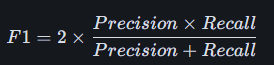

- Precision — модель оң деп болжаған нәтижелердің қаншасы шынымен дұрыс екенін көрсетеді.

- Recall — шын мәнінде оң болған нәтижелердің қаншасын модель дұрыс анықтағанын көрсетеді.

- F1-score — precision мен recall-дің гармоникалық орташасы; теңгерілмеген деректерде жиі қолданылады.


Жалған оң нәтижелер көбейген сайын precision және F1-score төмендейді. Ал азшылық класс үлгілері өткізіліп кетсе, recall және F1-score төмендейді. F1-score тек precision де, recall де жақсарғанда ғана жоғарылайды, сондықтан ол теңгерілмеген деректер үшін ыңғайлы метрика болып саналады.

## 2. Қайта таңдау (Resampling) әдістері

**Resampling** — класс өлшемдерін өзгертіп, оларды бір-біріне жақындату әдісі.

- **Oversampling (артықтау)** — азшылық класс үлгілерін көбейтеді немесе жаңа үлгілер жасайды. Мұның мақсаты — модель азшылық классқа қатысты көбірек заңдылықтарды үйренуі.

- **Undersampling (азайту)** — көпшілік класс үлгілерінің бір бөлігін алып тастайды. Осылайша деректер жиыны теңдестіріліп, барлық класс бірдей маңызға ие болады.

### Resampling-ді іске асыру

- Жасанды деректер арқылы бір азшылық және бір көпшілік класстан тұратын теңгерілмеген бинарлық деректер жиынын құрады.

- Теңестіру алдында әр классқа тиесілі үлгілердің бастапқы санын шығарады.

- Азшылық класс үлгілерін көбейтіп, деректер жиынын теңестіру үшін oversampling қолданады.

- Көпшілік класс үлгілерінің санын азайтып, класс арасындағы тепе-теңдікке қол жеткізу үшін undersampling қолданады.

In [1]:
import numpy as np
from sklearn.datasets import make_classification
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

X, y = make_classification(n_classes=2, class_sep=2, weights=[0.1, 0.9],
                           n_informative=3, n_redundant=1, flip_y=0,
                           n_features=20, n_clusters_per_class=1,
                           n_samples=1000, random_state=42)

print("Original class distribution:", Counter(y))

oversample = RandomOverSampler(sampling_strategy='minority')
X_over, y_over = oversample.fit_resample(X, y)
print("Oversampled class distribution:", Counter(y_over))

undersample = RandomUnderSampler(sampling_strategy='majority')
X_under, y_under = undersample.fit_resample(X, y)
print("Undersampled class distribution:", Counter(y_under))

Original class distribution: Counter({np.int64(1): 900, np.int64(0): 100})
Oversampled class distribution: Counter({np.int64(1): 900, np.int64(0): 900})
Undersampled class distribution: Counter({np.int64(0): 100, np.int64(1): 100})


### 3. Balanced Bagging Classifier

**Balanced Bagging Classifier** — кластардағы үлгілер саны тең болмаған кезде қолданылатын ансамбльдік әдіс. Яғни ол бірнеше модельдің болжамын біріктіріп, қорытынды шешім шығарады.

**Кластардағы үлгілер саны тең болмаған** деген - бұл бір санатқа жататын мысалдар көп, ал екінші санатқа жататын мысалдар аз деген сөз. Осындай жағдайды **кластардың теңгерімсіздігі** деп атайды.

МЫСАЛЫ

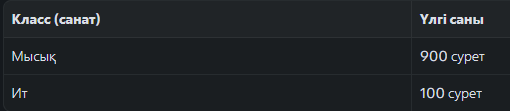

Бұл әдіс кәдімгі Bagging сияқты жұмыс істейді, бірақ әр модельді оқытуға арналған деректердегі кластардың санын теңестіреді. Соның арқасында үлгісі аз класс та оқыту кезінде назардан тыс қалмайды.


Кәдімгі модельдер үлгісі көп класқа көбірек бейімделіп, үлгісі аз класты нашар анықтауы мүмкін.

Balanced Bagging Classifier **Текст, выделенный полужирным шрифтом** осы мәселені шешу үшін оқыту барысында деректерді іштей қайта іріктейді.


### Balanced Bagging Classifier әдісін іске асыру

Бұл мысалда алдымен кластардағы үлгілер саны тең емес жасанды деректер жиынын құрамыз. Содан кейін кластардың саны теңестірілген, кездейсоқ әрі қайталап іріктелген деректерді пайдаланып, Random Forest моделін оқытамыз. Мақсат — модельдің үлгісі көп класты да, үлгісі аз класты да жақсы үйренуіне мүмкіндік беру.


Оқытудан кейін модельді тестілік деректермен тексеріп, оның үлгісі аз класты қаншалықты жақсы анықтайтынын бағалаймыз.


### 1-қадам. Қажетті кітапханаларды импорттау

- `make_classification` — кластардағы үлгілер саны тең емес жасанды деректер жиынын құрады.

- `BalancedBaggingClassifier` — оқыту кезінде кластар теңгерімсіздігін ескеретін ансамбльдік модель.

- `matplotlib` — нәтижелерді график түрінде көрсетуге арналған кітапхана.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import accuracy_score, classification_report

### 2-қадам. Кластары **теңгерімсіз** деректер жиынын құру

- `weights=[0.1, 0.9]` — үлгілердің 10%-ы бірінші класқа, ал 90%-ы екінші класқа тиесілі болатындай деректер жасайды.
- `random_state` — кодты қайта іске қосқанда бірдей нәтиже алуға мүмкіндік береді.

In [3]:
X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_classes=2,
    weights=[0.1, 0.9],
    n_informative=3,
    n_redundant=1,
    random_state=42
)

### 3-қадам: Кластардың таралуын визуализациялау

Бұл график деректер жиынында бір кластың басым екенін көрсетеді.

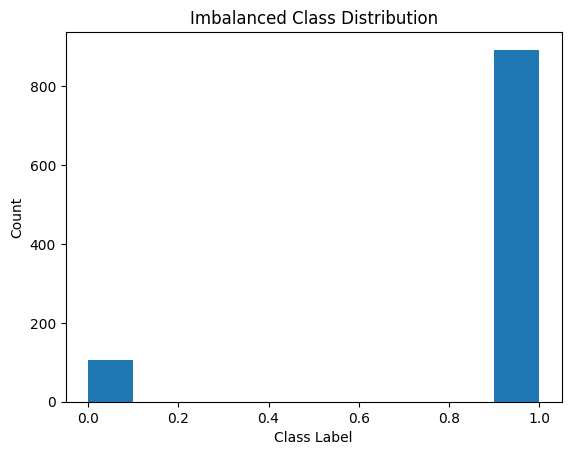

In [4]:
plt.figure()
plt.hist(y)
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.title("Imbalanced Class Distribution")
plt.show()

### **4-қадам: Деректер жиынын оқыту және тест жиындарына бөлу**

- Деректердің **80%-ы модельді оқытуға**, ал **20%-ы тестілеуге** қолданылады.
- Бірдей `random_state` мәні деректердің әр іске қосылған сайын бірдей бөлінуін қамтамасыз етеді.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### **5-қадам: Базалық классификаторды құру**

**Random Forest** базалық модель ретінде қолданылады.

In [6]:
base_classifier = RandomForestClassifier(random_state=42)

### **6-қадам: BalancedBaggingClassifier моделін құру**

- `sampling_strategy='auto'` — барлық кластарды автоматты түрде теңестіреді.
- `replacement=False` — бірдей үлгілердің қайталанып таңдалуына жол бермейді.

In [7]:
balanced_bagging = BalancedBaggingClassifier(
    estimator=base_classifier,
    sampling_strategy='auto',
    replacement=False,
    random_state=42
)

### **7-қадам: Модельді оқыту және болжам жасау**

Модель теңестірілген bootstrap үлгілері арқылы үйренеді.

In [8]:
balanced_bagging.fit(X_train, y_train)
y_pred = balanced_bagging.predict(X_test)

### **8-қадам: Модельді бағалау**

- `Accuracy` — модель болжамдарының жалпы дұрыстығын көрсетеді.
- `Classification report` — әр класс бойынша `precision`, `recall` және `F1-score` көрсеткіштерін береді.

In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.93
Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.72      0.65        18
           1       0.97      0.95      0.96       182

    accuracy                           0.93       200
   macro avg       0.78      0.84      0.81       200
weighted avg       0.94      0.93      0.93       200





---

### **4. Аз класты синтетикалық көбейту әдісі (SMOTE)**

[**SMOTE**](https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python/) — теңгерілмеген деректер жиынымен жұмыс істеуге арналған әдіс. Ол азшылық кластың бар үлгілерін жай ғана көшірмей, жаңа синтетикалық үлгілер жасайды.

SMOTE алгоритмінің жұмыс істеу реті:

1. Азшылық класқа жататын деректер нүктесі таңдалады.
2. Оның [**k ең жақын көршісі**](https://www.geeksforgeeks.org/machine-learning/k-nearest-neighbours/) анықталады.
3. Таңдалған нүкте мен оның көршілерінің бірінің арасынан жаңа синтетикалық деректер нүктесі құрылады.

### **SMOTE көмегімен кластардың теңгерімсіздігін өңдеу**

- Теңгерілмеген екі класты деректер жиынын құрып, оны оқыту және тест жиындарына бөледі.
- SMOTE қолданылғанға дейін оқыту деректеріндегі кластардың таралуын көрсетеді.
- Азшылық класқа жаңа синтетикалық үлгілер жасап, оқыту деректерін теңестіру үшін SMOTE әдісін қолданады.



In [11]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
X, y = make_classification(
    n_classes=2,
    class_sep=2,
    weights=[0.1, 0.9],
    n_informative=3,
    n_redundant=1,
    flip_y=0,
    n_features=20,
    n_clusters_per_class=1,
    n_samples=1000,
    random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Class distribution before SMOTE:", Counter(y_train))
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
print("Class distribution after SMOTE:", Counter(y_train_resampled))

Class distribution before SMOTE: Counter({np.int64(1): 713, np.int64(0): 87})
Class distribution after SMOTE: Counter({np.int64(1): 713, np.int64(0): 713})


### **5. Жіктеу шегін өзгерту (Threshold Moving)**

Жіктеу кезінде модель әр класқа тиесілі болу ықтималдығын есептейді. Әдетте ықтималдық **0,5-тен жоғары болса**, объект оң класқа жатқызылады.

Алайда теңгерілмеген деректерде `0.5` шегі әрдайым жақсы нәтиже бермейді. Мысалы, маңызды азшылық класты модель байқамай қалуы мүмкін.

Модельдің нәтижесін жақсарту үшін шешім қабылдау шегін өзгертуге болады:

- шекті **төмендетсек**, модель азшылық класқа жататын объектілерді көбірек анықтайды, бірақ жалған оң болжамдар артуы мүмкін;
- шекті **жоғарылатсақ**, жалған оң болжамдар азаяды, бірақ модель кейбір азшылық класс үлгілерін анықтамай қалуы мүмкін.


### **Ең тиімді шекті анықтау тәсілдері**

- **ROC қисығы:** дұрыс оң нәтижелер мен жалған оң нәтижелер арасындағы тиімді тепе-теңдікті қамтамасыз ететін шекті таңдау.
- **Precision–Recall қисығы:** теңгерілмеген деректер үшін өте пайдалы. Ол `precision` мен `recall` көрсеткіштері арасындағы тиімді тепе-теңдікті табуға көмектеседі.
- **Grid Search немесе диапазон бойынша тексеру:** бірнеше шекті, мысалы, `0.1`, `0.2`, `0.3` және т.б. қолданып көріп, ең жақсы нәтиже беретін мәнді таңдау.


### **Теңгерілмеген жіктеу үшін шекті баптау**

- Теңгерілмеген оқыту деректерімен [**Random Forest классификаторы**](https://www.geeksforgeeks.org/dsa/random-forest-classifier-using-scikit-learn/) оқытылады.
- Модель дайын класс белгілерінің орнына оң класқа тиесілі болу ықтималдығын болжайды.
- Шешім қабылдау шегі біртіндеп өзгертіліп, `F1-score` мәнінің қалай өзгеретіні бақыланады.
- Осылайша `precision` мен `recall` арасындағы тиімді тепе-теңдікті қамтамасыз ететін шек таңдалады.

In [12]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


X, y = make_classification(n_classes=2, class_sep=2, weights=[0.1, 0.9],
                           n_informative=3, n_redundant=1, flip_y=0,
                           n_features=20, n_clusters_per_class=1,
                           n_samples=1000, random_state=42)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)


y_proba = model.predict_proba(X_test)[:, 1]

threshold = 0.5


while threshold >= 0:
    y_pred = (y_proba >= threshold).astype(int)
    f1 = f1_score(y_test, y_pred)

    print(f"Threshold: {threshold:.2f}, F1 Score: {f1:.4f}")


    threshold -= 0.02

Threshold: 0.50, F1 Score: 1.0000
Threshold: 0.48, F1 Score: 1.0000
Threshold: 0.46, F1 Score: 1.0000
Threshold: 0.44, F1 Score: 1.0000
Threshold: 0.42, F1 Score: 1.0000
Threshold: 0.40, F1 Score: 1.0000
Threshold: 0.38, F1 Score: 1.0000
Threshold: 0.36, F1 Score: 1.0000
Threshold: 0.34, F1 Score: 1.0000
Threshold: 0.32, F1 Score: 1.0000
Threshold: 0.30, F1 Score: 1.0000
Threshold: 0.28, F1 Score: 0.9973
Threshold: 0.26, F1 Score: 0.9973
Threshold: 0.24, F1 Score: 0.9973
Threshold: 0.22, F1 Score: 0.9947
Threshold: 0.20, F1 Score: 0.9947
Threshold: 0.18, F1 Score: 0.9947
Threshold: 0.16, F1 Score: 0.9920
Threshold: 0.14, F1 Score: 0.9920
Threshold: 0.12, F1 Score: 0.9894
Threshold: 0.10, F1 Score: 0.9842
Threshold: 0.08, F1 Score: 0.9740
Threshold: 0.06, F1 Score: 0.9664
Threshold: 0.04, F1 Score: 0.9664
Threshold: 0.02, F1 Score: 0.9664


Бұл нәтиже жіктеу шегінің әртүрлі мәндерінде `F1-score` көрсеткішінің қалай өзгеретінін көрсетеді. Жоғарырақ шектерде, шамамен **0,30–0,50** аралығында, `F1-score` ең жоғары **1,0** мәніне жетеді. Ал шекті төмендеткен сайын `F1-score` біртіндеп азаяды. Бұл `precision` мен `recall` арасында өзара байланыс бар екенін көрсетеді: бір көрсеткіштің жақсаруы екіншісінің төмендеуіне әкелуі мүмкін.


### **6. Decision Tree қолдану**

**Decision Tree**, **Random Forest** және **Gradient Boosted Trees** сияқты ағашқа негізделген модельдер шешімдерді иерархиялық құрылым арқылы қабылдайды. Осы ерекшелік олардың теңгерілмеген деректермен ағашқа негізделмеген модельдерге қарағанда тиімдірек жұмыс істеуіне мүмкіндік береді.

- **Decision Tree — шешім ағашы.**  
  Шешім ағашы белгілердің мәндеріне қарай деректерді бірнеше аймаққа бөледі. Ол шешім шекараларын азшылық кластың ерекшеліктеріне бейімдей алады. Сондықтан теңгерілмеген деректерді анықтауда пайдалы болуы мүмкін. Алайда жеке шешім ағашы оқыту деректеріне шамадан тыс бейімделіп, `overfitting` мәселесіне ұшырауы мүмкін.

- **Random Forest — кездейсоқ орман.**  
  Random Forest — деректер мен белгілердің кездейсоқ бөліктерімен оқытылған көптеген шешім ағаштарының жиынтығы. Бірнеше ағаштың нәтижесін біріктіру арқылы модель шамадан тыс бейімделуді азайтады және жаңа деректерді жақсырақ жалпылайды. Сонымен қатар теңгерілмеген деректермен жұмыс істегенде жеке шешім ағашына қарағанда тұрақты нәтиже береді.

- **Gradient Boosted Trees — градиенттік бустинг ағаштары.**  
  Бұл әдісте шешім ағаштары бірінен кейін бірі құрылады. Әрбір жаңа ағаш алдыңғы ағаштардың жіберген қателерін түзетуге тырысады. Сондықтан модель қате жіктелген, соның ішінде азшылық класқа жататын үлгілерге көбірек көңіл бөледі. Бұл қасиет оны теңгерілмеген деректер үшін тиімді етеді. Дегенмен модель деректердегі шуға сезімтал болуы мүмкін.

### **7. Аномалияларды анықтау алгоритмдерін қолдану**


- **Аномалияларды немесе ауытқуларды анықтау алгоритмдері** — деректер жиынындағы сирек кездесетін, қалыпты деректерден ерекшеленетін үлгілерді анықтауға көмектесетін бір класты жіктеу алгоритмдері.

- Теңгерілмеген деректер жиынында **көпшілік класс** қалыпты деректер, ал **азшылық класс** аномалия немесе ауытқу ретінде қарастырылады.

- Мұндай алгоритмдер негізінен қалыпты деректермен оқытылады.

- Оқытылған модель жаңа деректің **қалыпты** немесе **аномалия** екенін анықтай алады.